# Principal Component Analysis (PCA) on a High-Dimensional Dataset
**Dataset:** Spambase (4,601 emails, 57 numeric features, binary label `spam`)

**Goals**
1. Apply PCA on a high-dimensional dataset
2. Compare the number of features before and after PCA
3. Visualize the reduced dimensions
4. Measure the impact on classification performance

**Workflow:** Load data → Preprocess → PCA → Compare features → Visualize → Classification impact

## 1. Imports

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset
Run the cell and upload `spambase.csv` when prompted (in Colab). If the file is already in the working directory, it is used directly.

In [ ]:
import os
if not os.path.exists("spambase.csv"):
    try:
        from google.colab import files
        files.upload()   # choose spambase.csv
    except ImportError:
        raise FileNotFoundError("Place spambase.csv in the working directory.")

df = pd.read_csv("spambase.csv")
print("Shape:", df.shape)
df.head()

Shape: (4601, 58)


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


## 3. Preprocessing

In [ ]:
# Quick data checks
print("Missing values  :", df.isna().sum().sum())
print("Duplicate rows  :", df.duplicated().sum())
print("\nClass distribution:")
print(df["spam"].value_counts().rename({0: "Not spam", 1: "Spam"}))

Missing values  : 0
Duplicate rows  : 391

Class distribution:
spam
Not spam    2788
Spam        1813
Name: count, dtype: int64


In [ ]:
# Remove duplicate rows (they add no new information and can leak between train/test)
df = df.drop_duplicates().reset_index(drop=True)

X = df.drop(columns="spam")
y = df["spam"]
print("Shape after dropping duplicates:", X.shape)

Shape after dropping duplicates: (4210, 57)


**Train/test split first, then scaling.** PCA is driven by variance, so features must be on the same scale
(e.g. `capital_run_length_total` is in the thousands while `word_freq_*` is mostly < 1).
The scaler and PCA are **fit on the training set only** to avoid data leakage.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print("Train:", X_train_sc.shape, "| Test:", X_test_sc.shape)

Train: (3368, 57) | Test: (842, 57)


## 4. Apply PCA
First fit PCA with **all** components to study how much variance each one explains.

In [ ]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_sc)

evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

n_90 = np.argmax(cum >= 0.90) + 1
n_95 = np.argmax(cum >= 0.95) + 1
n_99 = np.argmax(cum >= 0.99) + 1
print(f"Components for 90% variance: {n_90}")
print(f"Components for 95% variance: {n_95}")
print(f"Components for 99% variance: {n_99}")

Components for 90% variance: 43
Components for 95% variance: 48
Components for 99% variance: 54


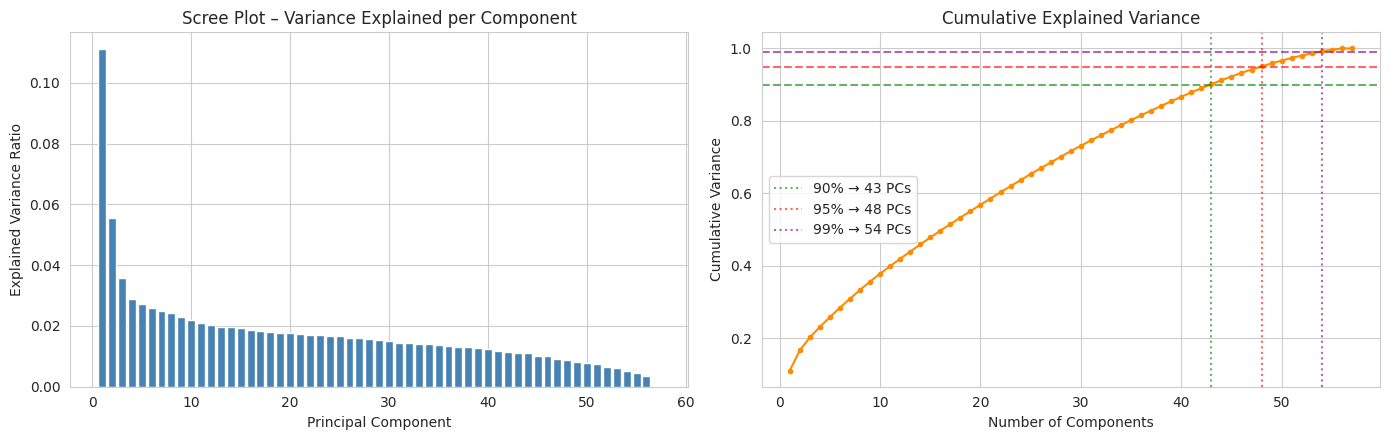

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# Scree plot
ax[0].bar(range(1, len(evr) + 1), evr, color="steelblue")
ax[0].set_title("Scree Plot – Variance Explained per Component")
ax[0].set_xlabel("Principal Component")
ax[0].set_ylabel("Explained Variance Ratio")

# Cumulative variance
ax[1].plot(range(1, len(cum) + 1), cum, marker="o", ms=3, color="darkorange")
for thr, n, c in [(0.90, n_90, "green"), (0.95, n_95, "red"), (0.99, n_99, "purple")]:
    ax[1].axhline(thr, ls="--", color=c, alpha=0.6)
    ax[1].axvline(n, ls=":", color=c, alpha=0.6, label=f"{int(thr*100)}% → {n} PCs")
ax[1].set_title("Cumulative Explained Variance")
ax[1].set_xlabel("Number of Components")
ax[1].set_ylabel("Cumulative Variance")
ax[1].legend()

plt.tight_layout()
plt.show()

Now fit the final PCA, keeping enough components to retain **95% of the variance**.

In [ ]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_sc)
X_test_pca  = pca.transform(X_test_sc)

print("Components kept          :", pca.n_components_)
print("Variance retained        : {:.2%}".format(pca.explained_variance_ratio_.sum()))

Components kept          : 48
Variance retained        : 95.05%


## 5. Features before vs. after PCA

,Stage,Number of features,Train matrix shape,Variance retained
0,Before PCA (scaled),57,"(3368, 57)",100%
1,After PCA (95% variance),48,"(3368, 48)",95.05%


Dimensionality reduced by 15.8%  (57 → 48)


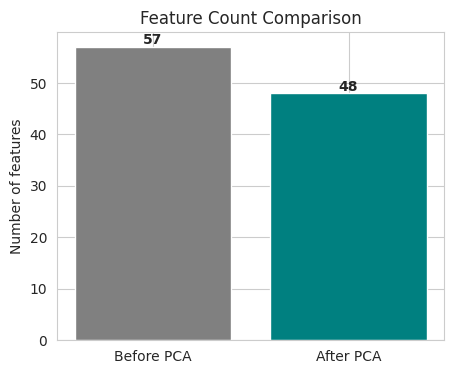

In [ ]:
n_before, n_after = X_train_sc.shape[1], X_train_pca.shape[1]

comparison = pd.DataFrame({
    "Stage": ["Before PCA (scaled)", "After PCA (95% variance)"],
    "Number of features": [n_before, n_after],
    "Train matrix shape": [X_train_sc.shape, X_train_pca.shape],
    "Variance retained": ["100%", f"{pca.explained_variance_ratio_.sum():.2%}"],
})
display(comparison)
print(f"Dimensionality reduced by {(1 - n_after/n_before):.1%}  ({n_before} → {n_after})")

plt.figure(figsize=(5, 4))
plt.bar(["Before PCA", "After PCA"], [n_before, n_after], color=["gray", "teal"])
for i, v in enumerate([n_before, n_after]):
    plt.text(i, v + 0.5, str(v), ha="center", fontweight="bold")
plt.ylabel("Number of features")
plt.title("Feature Count Comparison")
plt.show()

## 6. Visualization of reduced dimensions

### 6.1 PCA projected to 2D

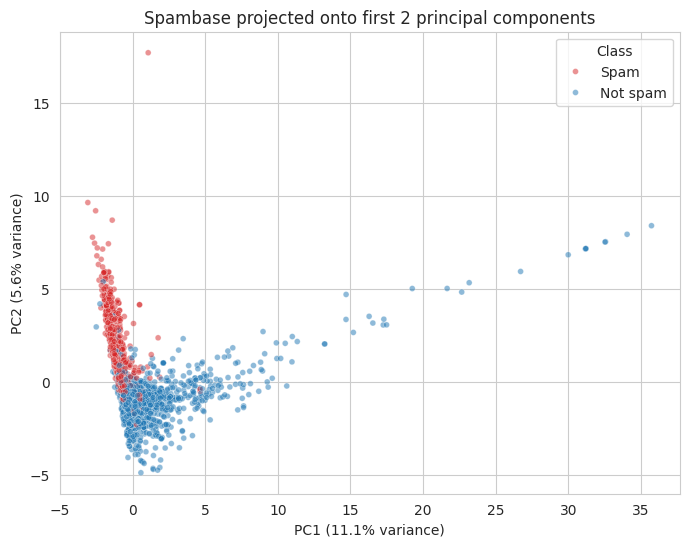

Variance captured by 2 PCs: 16.66%


In [ ]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X_train_sc)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y_train.map({0: "Not spam", 1: "Spam"}),
                palette={"Not spam": "tab:blue", "Spam": "tab:red"}, alpha=0.5, s=18)
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)")
plt.title("Spambase projected onto first 2 principal components")
plt.legend(title="Class")
plt.show()

print("Variance captured by 2 PCs: {:.2%}".format(pca_2d.explained_variance_ratio_.sum()))

### 6.2 PCA projected to 3D

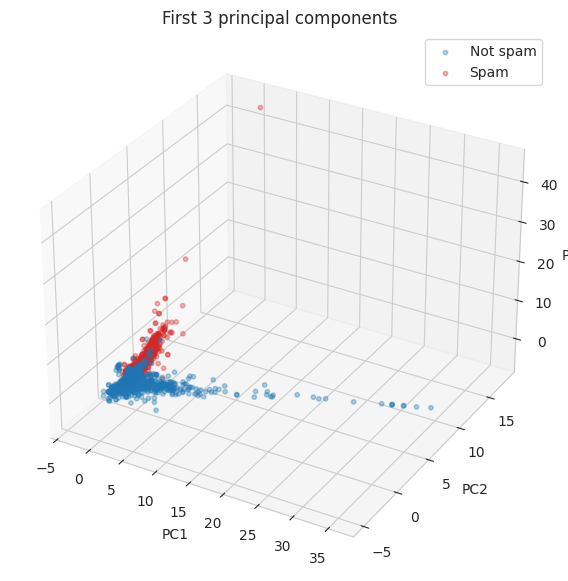

Variance captured by 3 PCs: 20.25%


In [ ]:
pca_3d = PCA(n_components=3, random_state=RANDOM_STATE)
X_3d = pca_3d.fit_transform(X_train_sc)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
for label, color, name in [(0, "tab:blue", "Not spam"), (1, "tab:red", "Spam")]:
    m = (y_train.values == label)
    ax.scatter(X_3d[m, 0], X_3d[m, 1], X_3d[m, 2], c=color, alpha=0.35, s=10, label=name)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("First 3 principal components")
ax.legend()
plt.show()

print("Variance captured by 3 PCs: {:.2%}".format(pca_3d.explained_variance_ratio_.sum()))

### 6.3 What do the components represent? (loadings)

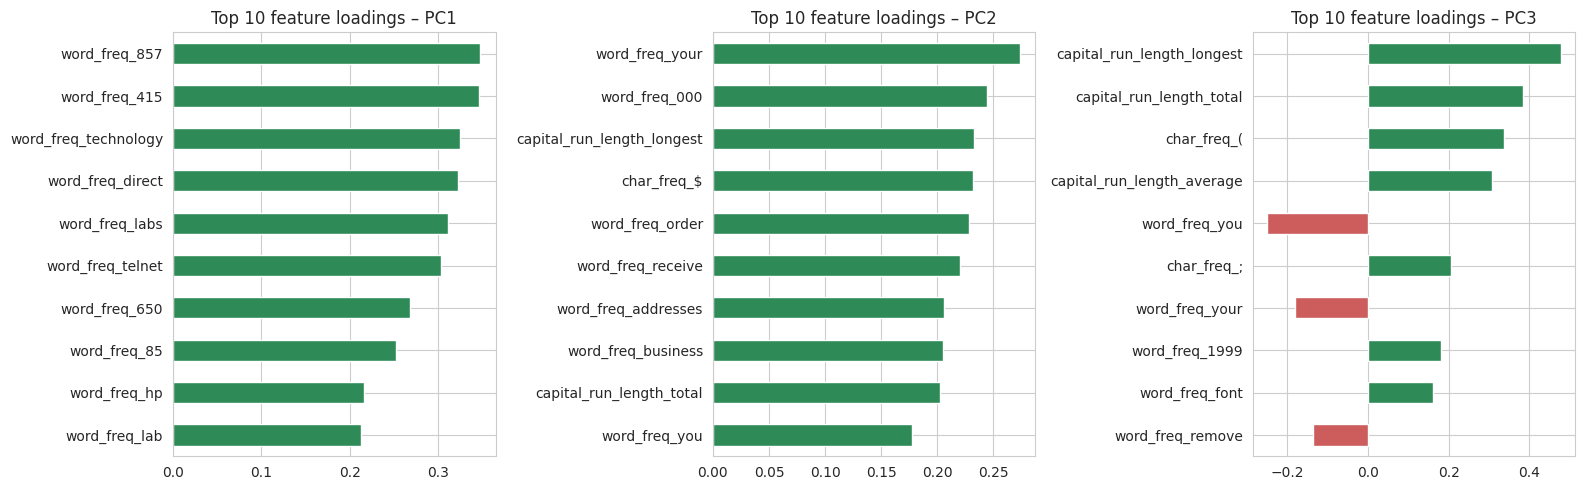

In [ ]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, pc in zip(axes, loadings.columns):
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index)[:10]
    top[::-1].plot.barh(ax=ax, color=np.where(top[::-1] > 0, "seagreen", "indianred"))
    ax.set_title(f"Top 10 feature loadings – {pc}")
plt.tight_layout()
plt.show()

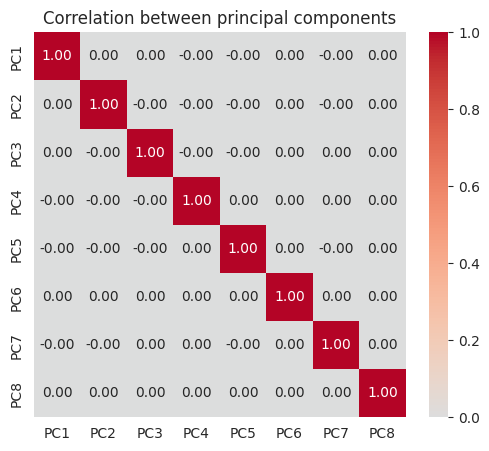

In [ ]:
# Heatmap of correlation between the first PCs (should be ~0: components are orthogonal)
pc_df = pd.DataFrame(X_train_pca[:, :8], columns=[f"PC{i+1}" for i in range(8)])
plt.figure(figsize=(6, 5))
sns.heatmap(pc_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between principal components")
plt.show()

## 7. Impact on classification performance
Same models, trained on (a) all original scaled features, (b) PCA with 95% variance, (c) only 2 PCs.

In [ ]:
def evaluate(model, Xtr, Xte, name, setup):
    t0 = time.time()
    model.fit(Xtr, y_train)
    train_time = time.time() - t0
    pred = model.predict(Xte)
    return {
        "Model": name, "Features": setup, "n_features": Xtr.shape[1],
        "Accuracy": accuracy_score(y_test, pred),
        "F1 (spam)": f1_score(y_test, pred),
        "Train time (s)": train_time,
    }

setups = {
    "Original (scaled)": (X_train_sc, X_test_sc),
    "PCA (95% variance)": (X_train_pca, X_test_pca),
    "PCA (2 components)": (pca_2d.transform(X_train_sc), pca_2d.transform(X_test_sc)),
}

models = {
    "Logistic Regression": lambda: LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}

rows = []
for mname, make in models.items():
    for sname, (Xtr, Xte) in setups.items():
        rows.append(evaluate(make(), Xtr, Xte, mname, sname))

results = pd.DataFrame(rows)
results.style.format({"Accuracy": "{:.4f}", "F1 (spam)": "{:.4f}", "Train time (s)": "{:.3f}"})

,Model,Features,n_features,Accuracy,F1 (spam),Train time (s)
0,Logistic Regression,Original (scaled),57,0.9347,0.9170,0.042
1,Logistic Regression,PCA (95% variance),48,0.9299,0.9102,0.020
2,Logistic Regression,PCA (2 components),2,0.8860,0.8505,0.006
3,Random Forest,Original (scaled),57,0.9442,0.9293,2.262
4,Random Forest,PCA (95% variance),48,0.9406,0.9251,4.604
5,Random Forest,PCA (2 components),2,0.8836,0.8546,1.089


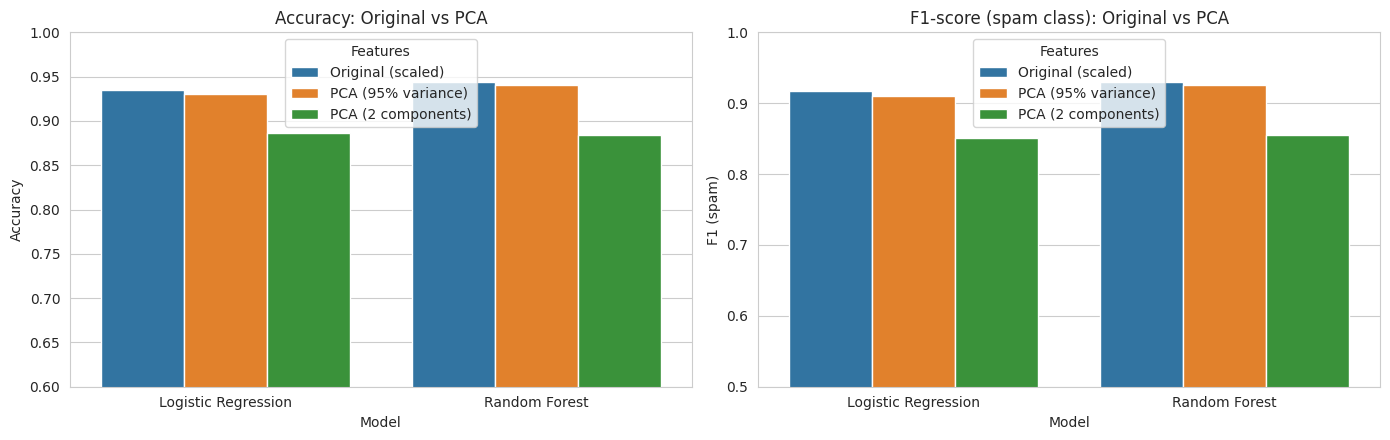

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=results, x="Model", y="Accuracy", hue="Features", ax=ax[0])
ax[0].set_ylim(0.6, 1.0); ax[0].set_title("Accuracy: Original vs PCA")
sns.barplot(data=results, x="Model", y="F1 (spam)", hue="Features", ax=ax[1])
ax[1].set_ylim(0.5, 1.0); ax[1].set_title("F1-score (spam class): Original vs PCA")
plt.tight_layout()
plt.show()

### Accuracy vs. number of principal components

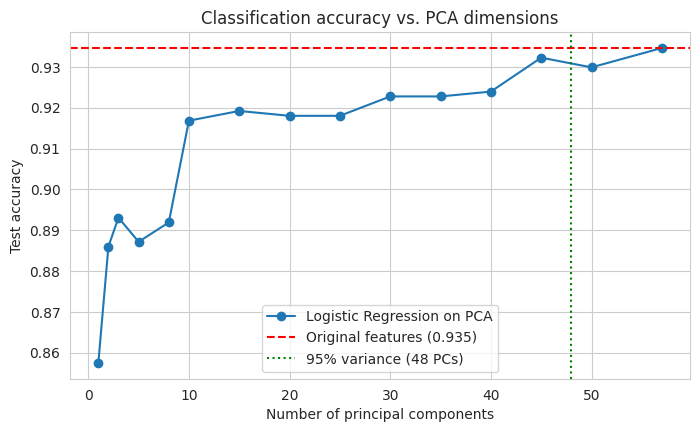

In [ ]:
ks = [1, 2, 3, 5, 8, 10, 15, 20, 25, 30, 35, 40, 45, 50, 57]
accs = []
for k in ks:
    p = PCA(n_components=k, random_state=RANDOM_STATE).fit(X_train_sc)
    clf = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
    clf.fit(p.transform(X_train_sc), y_train)
    accs.append(accuracy_score(y_test, clf.predict(p.transform(X_test_sc))))

base_acc = results.query("Model=='Logistic Regression' and Features=='Original (scaled)'")["Accuracy"].iloc[0]

plt.figure(figsize=(8, 4.5))
plt.plot(ks, accs, marker="o", label="Logistic Regression on PCA")
plt.axhline(base_acc, color="red", ls="--", label=f"Original features ({base_acc:.3f})")
plt.axvline(n_95, color="green", ls=":", label=f"95% variance ({n_95} PCs)")
plt.xlabel("Number of principal components"); plt.ylabel("Test accuracy")
plt.title("Classification accuracy vs. PCA dimensions")
plt.legend(); plt.show()

## 8. Summary

In [ ]:
lr = results[results.Model == "Logistic Regression"].set_index("Features")
rf = results[results.Model == "Random Forest"].set_index("Features")

print(f"Features         : {n_before} → {n_after}  ({(1 - n_after/n_before):.0%} fewer) retaining {pca.explained_variance_ratio_.sum():.1%} variance")
print(f"2 PCs / 3 PCs    : capture {pca_2d.explained_variance_ratio_.sum():.1%} / {pca_3d.explained_variance_ratio_.sum():.1%} of variance (classes partly separable, but overlap)")
print()
for name, r in [("Logistic Regression", lr), ("Random Forest", rf)]:
    print(f"{name}:")
    for s in r.index:
        print(f"   {s:<20} acc={r.loc[s,'Accuracy']:.4f}  f1={r.loc[s,'F1 (spam)']:.4f}")

Features         : 57 → 48  (16% fewer) retaining 95.0% variance
2 PCs / 3 PCs    : capture 16.7% / 20.3% of variance (classes partly separable, but overlap)

Logistic Regression:
   Original (scaled)    acc=0.9347  f1=0.9170
   PCA (95% variance)   acc=0.9299  f1=0.9102
   PCA (2 components)   acc=0.8860  f1=0.8505
Random Forest:
   Original (scaled)    acc=0.9442  f1=0.9293
   PCA (95% variance)   acc=0.9406  f1=0.9251
   PCA (2 components)   acc=0.8836  f1=0.8546
